In [171]:
# population studies using multi-class classification
import numpy as np
import pandas as pd
import sys
from matplotlib import pyplot

if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util


In [10]:
if 1:
    import importlib
    importlib.reload(util);


In [201]:
# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' 
    #baseline_case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_RF' # '4FGL-DR4_GMM_RF_no_prune'
elif cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_GMM_RF'
    case = '4FGL-DR3_GMM_RF' 

baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)


cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')

cat_folder = '%s/results/%s_probabilistic_catalogs/' % (cdict['root_folder'], util.get_cat_descr(cdict))
cat_fn = cat_folder + util.get_cat_descr(cdict) + '_prob_cat.csv'
cat_df = pd.read_csv(cat_fn, index_col=0)
unas_mask = (cat_df['CLASS1'] == 'unas') | (cat_df['CLASS1'] == 'unk')

tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]


cls = ['psr', 'msp']
cl_inds = [util.get_cl_ind(dec_tree_cat_dict, cl) for cl in cls]

In [202]:
fnt = '../../data_in/gu_candidates.csv'
toby_df = pd.read_csv(fnt, index_col=0)
if cl == 'msp':
    toby_clm = 'pdf_MSP'
elif cl == 'psr':
    toby_clm = 'pdf_young'
else:
    topy_clm = None

In [203]:
dec_tree_cat_dict

{1: ['nlsy1', 'css', 'fsrq'],
 2: ['ssrq', 'rdg', 'sbg', 'sey', 'bll', 'agn'],
 3: ['hmb', 'psr', 'lmb', 'nov'],
 4: ['bin', 'snr', 'gc', 'sfr', 'pwn'],
 5: ['glc', 'gal', 'msp']}

In [204]:
cols = ['prob_%s+' % cl for cl in cls]
if toby_clm is not None:
    toby_clm_out = '%s_Toby' % toby_clm
    cols.append(toby_clm_out)
indices = [name[:17] for name in cat_df.index]
out_df = pd.DataFrame(index=indices, columns=cols, data=-np.ones((len(cat_df.index), len(cols))))

In [205]:
#tnames = np.array(toby_df.index, dtype=str)

In [206]:
for i, cl in enumerate(cls):
    clm_out = 'prob_%s+' % cl
    clm_in = '%i_RF' % cl_inds[i]
    out_df[clm_out] = cat_df[clm_in].values
out_df[toby_clm_out].loc[toby_df.index] = toby_df[toby_clm].loc[toby_df.index]
out_df = out_df[np.array(unas_mask)]


In [207]:
sum(out_df[toby_clm_out] > -0.1), len(toby_df)

(478, 479)

In [208]:
out_df = out_df.sort_values(by=clm_out, ascending=False)

In [209]:
np.sum(out_df)

prob_psr+          327.399131
prob_msp+          582.066590
pdf_young_Toby   -2041.644000
dtype: float64

In [210]:
np.array(out_df[clm_out])[:100]

array([0.99361702, 0.99101377, 0.98510638, 0.97856383, 0.97101377,
       0.96553191, 0.96382979, 0.96379433, 0.95996454, 0.95191489,
       0.95145289, 0.94893617, 0.94851064, 0.94613374, 0.93932624,
       0.93467984, 0.93311955, 0.93292583, 0.93217298, 0.93172699,
       0.93119006, 0.92686796, 0.9232468 , 0.92248227, 0.92013153,
       0.9187234 , 0.91297449, 0.90914894, 0.9051773 , 0.90510638,
       0.90379331, 0.90319308, 0.90209119, 0.89704214, 0.8968812 ,
       0.89617021, 0.89613374, 0.89315603, 0.88893617, 0.88866261,
       0.88406327, 0.8803449 , 0.87677305, 0.87430073, 0.87131153,
       0.86744681, 0.86204119, 0.8616698 , 0.85382877, 0.85145289,
       0.84961214, 0.84937225, 0.84914894, 0.84532299, 0.84465957,
       0.84448936, 0.84238076, 0.84098007, 0.83657345, 0.83517868,
       0.83085106, 0.83081958, 0.8293617 , 0.82931164, 0.81873759,
       0.81869849, 0.81255808, 0.80578306, 0.80553191, 0.8018926 ,
       0.80173687, 0.79747817, 0.79735065, 0.79550963, 0.79485

In [211]:
np.array(out_df[toby_clm_out])[:100]

array([-1.   , -1.   , -1.   , -1.   , -1.   , -1.   , -1.   , -1.   ,
       -1.   , -1.   ,  0.077, -1.   , -1.   ,  0.122, -1.   ,  0.226,
       -1.   , -1.   , -1.   , -1.   , -1.   ,  0.094,  0.151, -1.   ,
       -1.   , -1.   , -1.   , -1.   , -1.   , -1.   ,  0.082, -1.   ,
        0.005, -1.   , -1.   , -1.   ,  0.1  , -1.   , -1.   , -1.   ,
       -1.   , -1.   , -1.   , -1.   , -1.   , -1.   , -1.   , -1.   ,
        0.036,  0.162,  0.407, -1.   , -1.   , -1.   ,  0.152,  0.273,
       -1.   ,  0.099,  0.204, -1.   , -1.   ,  0.455, -1.   ,  0.07 ,
        0.236, -1.   , -1.   ,  0.079,  0.01 ,  0.196, -1.   ,  0.151,
        0.207,  0.12 ,  0.112,  0.09 , -1.   , -1.   , -1.   ,  0.085,
       -1.   ,  0.081,  0.13 ,  0.148, -1.   ,  0.342, -1.   , -1.   ,
       -1.   ,  0.146,  0.014,  0.12 ,  0.202,  0.107, -1.   ,  0.002,
       -1.   ,  0.142, -1.   ,  0.095])

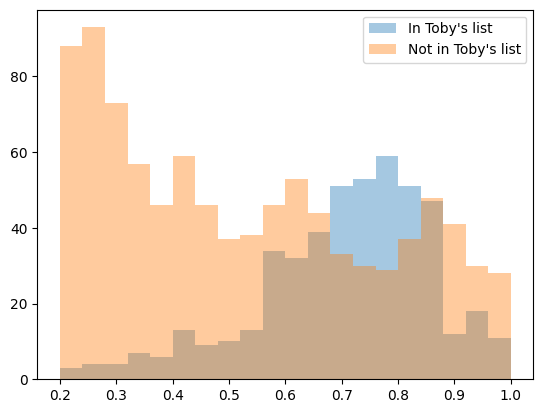

In [212]:
ps = 0.
for i, cl in enumerate(cls):
    clm_out = 'prob_%s+' % cl
    ps += out_df[clm_out]
pyplot.figure()
tmask = out_df[toby_clm_out] > -0.1
bins = np.linspace(0.2, 1, 21)
pyplot.hist(ps[tmask], alpha=0.4, density=False, bins=bins, label="In Toby's list");
pyplot.hist(ps[~tmask], alpha=0.4, density=False, bins=bins, label="Not in Toby's list");
pyplot.legend()
#pyplot.title('%s-like sources' % cl.upper());